# 04 · Audit and health — can the reports be trusted?

A report is only useful if it describes reality. This notebook re-reads every
report file and then goes to the **bytes on disk** to check the claims:

* does every row in `manifest.csv` have a status?
* is every stored file actually there, with the recorded size and SHA-256?
* does the resume index (`state.json`) cover everything that was fetched?
* were there errors, and is the listing-page audit trail complete?

Every check is reported as PASS / FAIL / INFO with the numbers behind it.

In [1]:
import os
import sys

# Make the shared loader importable whether the kernel started in the repo root
# or in notebooks/.
CWD = os.getcwd()
for _cand in (os.path.join(CWD, "notebooks"), CWD, os.path.dirname(CWD)):
    if os.path.isfile(os.path.join(_cand, "dadosabertos_data.py")):
        sys.path.insert(0, _cand)
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

import dadosabertos_data as d

plt = d.setup_plots()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 70)

print("repository root :", d.ROOT)
print("loader module   :", os.path.dirname(d.__file__))
for _t in d.TREES:
    print(f"  {_t:<16} {len(d.site_dirs(_t))} site folders")

repository root : /home/user/dadosabertos
loader module   : /home/user/dadosabertos/notebooks
  outputs          5 site folders
  outputs-replica  6 site folders


In [2]:
checks = []


def check(name, ok, detail):
    verdict = "PASS" if ok else "FAIL"
    checks.append({"check": name, "result": verdict, "detail": detail})
    return ok


run = d.load_manifest("outputs-replica")
summary = d.load_summary("outputs-replica")
dups = d.load_duplicates("outputs-replica")
state = d.load_state("outputs-replica")
stored = d.stored_files("outputs-replica")
verify = d.verify_against_disk("outputs-replica")

# 1 - every manifest row carries a status
missing_status = int(run["status"].isna().sum())
check(
    "every manifest row has a status",
    missing_status == 0,
    f"{len(run)} rows, {missing_status} without a status",
)

# 2 - no per-file errors anywhere in either tree
err_rows = 0
for tree in d.TREES:
    for site, path in d.site_dirs(tree):
        p = os.path.join(path, "_reports", "errors.log")
        if os.path.isfile(p):
            err_rows += sum(1 for line in open(p, encoding="utf-8") if line.strip())
check("errors.log is empty in every site", err_rows == 0, f"{err_rows} error lines across both trees")

# 3 - every manifest entry is on disk
not_on_disk = int((~verify["on_disk"]).sum())
check("every stored document exists on disk", not_on_disk == 0, f"{len(verify)} checked, {not_on_disk} missing")

# 4 - sizes match
bad_size = int((~verify["size_matches"]).sum())
check("manifest size == bytes on disk", bad_size == 0, f"{bad_size} mismatches")

# 5 - hashes match
run_hashed = verify[verify["manifest_sha256"].notna()]
bad_hash = int((~run_hashed["sha256_matches"]).sum())
check(
    "manifest SHA-256 == SHA-256 of the stored file",
    bad_hash == 0,
    f"{len(run_hashed)} hashed documents, {bad_hash} mismatches",
)

# 6 - resume index covers the fetched documents
check(
    "state.json indexes every document in the manifest",
    len(state) >= len(run),
    f"{len(state)} urls in state.json, {len(run)} rows in the manifests",
)

# 7 - every collapse is backed by a hash we know
known = set(run["sha256"].dropna())
check(
    "every duplicate row cites a known content hash",
    bool(set(dups["sha256"]) <= known),
    f"{len(set(dups['sha256']))} collapsed hashes, all present in the manifest: "
    f"{set(dups['sha256']) <= known}",
)

# 8 - the audit trail covers every crawled listing page
pages = pd.concat([d.index_pages(t) for t in d.TREES], ignore_index=True)
rep_pages = int(summary["listing_pages"].sum())
out_pages = int((pages["tree"] == "outputs-replica").sum())
check(
    "a listing page was saved for every page crawled",
    out_pages >= rep_pages,
    f"{out_pages} pages under _index/pages/, summaries report {rep_pages}",
)

display(pd.DataFrame(checks).style.hide(axis="index"))
failed = [c for c in checks if c["result"] == "FAIL"]
print(f"{len(checks) - len(failed)}/{len(checks)} checks passed" + ("" if not failed else f" — failures: {[c['check'] for c in failed]}"))

check,result,detail
every manifest row has a status,PASS,"39 rows, 0 without a status"
errors.log is empty in every site,PASS,0 error lines across both trees
every stored document exists on disk,PASS,"39 checked, 0 missing"
manifest size == bytes on disk,PASS,0 mismatches
manifest SHA-256 == SHA-256 of the stored file,PASS,"39 hashed documents, 0 mismatches"
state.json indexes every document in the manifest,PASS,"39 urls in state.json, 39 rows in the manifests"
every duplicate row cites a known content hash,PASS,"8 collapsed hashes, all present in the manifest: True"
a listing page was saved for every page crawled,PASS,"24 pages under _index/pages/, summaries report 24"


8/8 checks passed


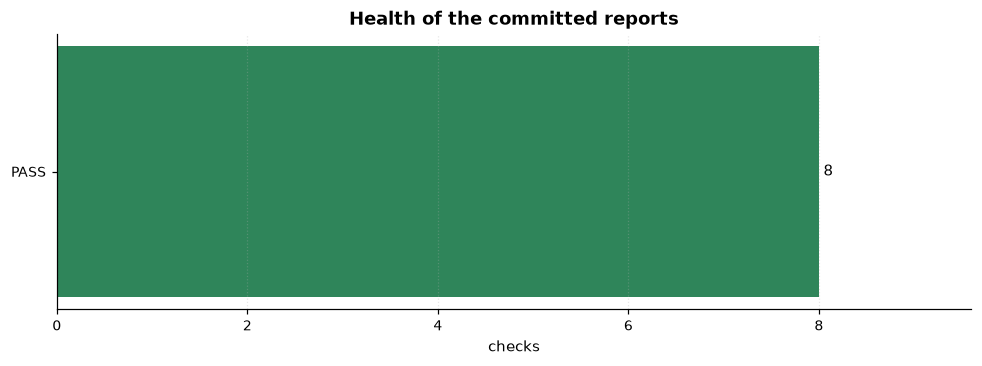

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.4))
res = pd.DataFrame(checks)["result"].value_counts()
colors = {"PASS": "#2f855a", "FAIL": "#c53030"}.get
bars = ax.barh(res.index, res.to_numpy(dtype=float), color=[colors(i, "#4c51bf") for i in res.index])
ax.bar_label(bars, padding=3, fontsize=10)
ax.set_xlabel("checks")
ax.set_title("Health of the committed reports")
ax.set_xlim(0, res.max() * 1.2)
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

## 1 · Byte-level verification

`verify_against_disk()` re-hashes every file under `<site>/files/` and compares
it with what the manifest recorded. This is the check that turns “the report
says it worked” into “the bytes are there”.

site,name,status,manifest_size,disk_size,short_sha,sha256_matches,nlink
comissaodaverdade.al.sp.gov.br,001 - Ficha DEOPS Paulo Roberto Pinto.pdf,downloaded,52.0 KiB,52.0 KiB,4c45df4d0470,True,1
comissaodaverdade.al.sp.gov.br,001-Antonio-Raymundo-Lucena.pdf,downloaded,140.0 KiB,140.0 KiB,a807912f33c5,True,1
comissaodaverdade.al.sp.gov.br,001-Arquivo-CEMDP-Joao-Carlos-Cavalcanti-Reis.pdf,downloaded,88.0 KiB,88.0 KiB,302000e3cd88,True,1
comissaodaverdade.al.sp.gov.br,001-Arquivo-CEMDP-Joao-Carlos-Cavalcanti-Reis004.pdf,duplicate,88.0 KiB,88.0 KiB,302000e3cd88,True,1
comissaodaverdade.al.sp.gov.br,001-ArquivoCEMDP-devanir.pdf,downloaded,33.0 KiB,33.0 KiB,c395464b53db,True,1
comissaodaverdade.al.sp.gov.br,001-ArquivoCEMDP.pdf,duplicate,33.0 KiB,33.0 KiB,c395464b53db,True,1
comissaodaverdade.al.sp.gov.br,001-CartaLilianRuggia1.jpg,downloaded,76.0 KiB,76.0 KiB,f8be19c93d07,True,1
comissaodaverdade.al.sp.gov.br,001-Certidao-de-casamento.pdf,downloaded,237.0 KiB,237.0 KiB,698d66e90b82,True,1
dados.cvm.gov.br,ADM_CART_CAD_2024.zip,downloaded,64.0 KiB,64.0 KiB,2bc0e4689387,True,1
dados.cvm.gov.br,ADM_CART_CAD_2025.zip,downloaded,51.0 KiB,51.0 KiB,7fdb31a1b887,True,1


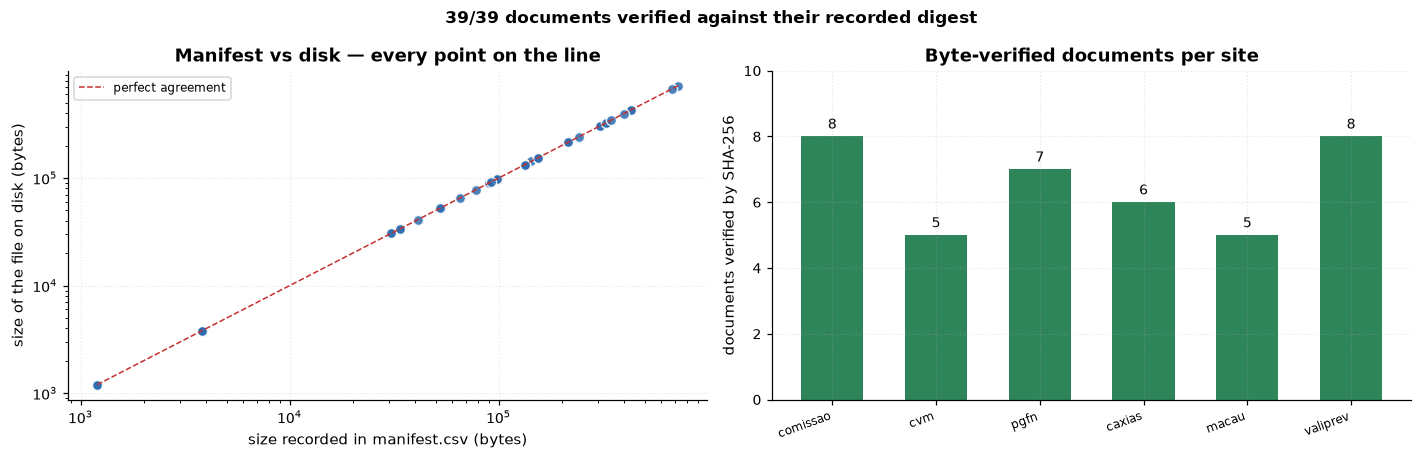

In [4]:
show = verify.assign(
    manifest_size=verify["manifest_size"].map(d.human_bytes),
    disk_size=verify["disk_size"].map(d.human_bytes),
    short_sha=verify["disk_sha256"].str.slice(0, 12),
)[["site", "name", "status", "manifest_size", "disk_size", "short_sha", "sha256_matches", "nlink"]]
display(show.head(12).style.hide(axis="index"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].scatter(
    verify["manifest_size"], verify["disk_size"], s=44, alpha=0.85, color="#2b6cb0", edgecolor="white"
)
lo = float(min(verify["manifest_size"].min(), verify["disk_size"].min()))
hi = float(max(verify["manifest_size"].max(), verify["disk_size"].max()))
axes[0].plot([lo, hi], [lo, hi], ls="--", color="#c53030", lw=1, label="perfect agreement")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("size recorded in manifest.csv (bytes)")
axes[0].set_ylabel("size of the file on disk (bytes)")
axes[0].set_title("Manifest vs disk — every point on the line")
axes[0].legend(fontsize=8)

by_site = verify.groupby("site").agg(
    documents=("name", "count"), verified=("sha256_matches", "sum")
)
by_site["verified"] = by_site["verified"].astype(int)
x = range(len(by_site))
axes[1].bar(x, by_site["documents"].to_numpy(dtype=float), 0.6, color="#2f855a")
axes[1].bar_label(axes[1].containers[0], padding=3, fontsize=9)
axes[1].set_xticks(list(x))
axes[1].set_xticklabels([d.short_site(s) for s in by_site.index], rotation=20, ha="right", fontsize=8)
axes[1].set_ylabel("documents verified by SHA-256")
axes[1].set_title("Byte-verified documents per site")
axes[1].set_ylim(0, by_site["documents"].max() * 1.25)

fig.suptitle(f"{int(verify['sha256_matches'].sum())}/{len(verify)} documents verified against their recorded digest", fontweight="bold")
fig.tight_layout()
plt.show()

### A note on hard links

`duplicates.csv` records `action = "stored as hardlink"`, and during the run the
duplicate really was one inode shared under two names. In this **checkout** every
file shows `nlink = 1`, because Git stores each path as an independent blob and
restores it as a separate file. The sharing is not lost — it is just not a
filesystem property any more. Verify byte-identity with the `sha256` columns
instead of `st_nlink`, or re-run `python3 tools/replica_demo.py` to see the
inodes for yourself.

In [5]:
links = verify.groupby(["site", "status"])["nlink"].agg(["count", "min", "max"])
display(links.rename(columns={"count": "documents"}))

same_hash = (
    verify.dropna(subset=["disk_sha256"])
    .groupby("disk_sha256")
    .agg(paths=("local_path", lambda s: ", ".join(sorted(s))[:70]), copies=("local_path", "count"))
    .sort_values("copies", ascending=False)
)
same_hash = same_hash[same_hash["copies"] > 1]
display(
    Markdown(
        f"**{len(same_hash)} content hashes are stored under more than one path** — "
        "the duplicates are byte-identical, whatever `nlink` says in a Git checkout."
    )
)
same_hash = same_hash.reset_index()
same_hash["sha256 (12)"] = same_hash["disk_sha256"].str.slice(0, 12)
display(same_hash[["sha256 (12)", "copies", "paths"]])

documents  min  max
site                           status                         
comissaodaverdade.al.sp.gov.br downloaded          6    1    1
                               duplicate           2    1    1
dados.cvm.gov.br               downloaded          4    1    1
                               duplicate           1    1    1
dadosabertos.pgfn.gov.br       downloaded          4    1    1
                               duplicate           3    1    1
geofiles.caxias.rs.gov.br      downloaded          6    1    1
macau.rn.gov.br                downloaded          4    1    1
                               duplicate           1    1    1
valiprev.sp.gov.br             downloaded          6    1    1
                               duplicate           2    1    1

**8 content hashes are stored under more than one path** — the duplicates are byte-identical, whatever `nlink` says in a Git checkout.

,sha256 (12),copies,paths
0,a077779091c9,3,uploads/paginas/certidoes/pdf/10_2023-LGPD-ARTE-VISUAL-E-IMPRESSAO...
1,302000e3cd88,2,"001-Arquivo-CEMDP-Joao-Carlos-Cavalcanti-Reis.pdf, 001-Arquivo-CEM..."
2,b4183265d26e,2,2013 - Diário Oficial de Macau/01 - Janeiro-2013/macau-2013-01-02....
3,b3f1d00fb562,2,"2025_trimestre_03/Dados_abertos_Nao_Previdenciario.zip, 2025_trime..."
4,a92b87949ab0,2,"CIA_ABERTA/cia_aberta_doc_2025.zip, FIDC/fidc_doc_2025.zip"
5,46280c782398,2,"2025_trimestre_03/Dados_abertos_Previdenciario.zip, 2025_trimestre..."
6,f82f79411cd8,2,"2025_trimestre_03/Dados_abertos_FGTS.zip, 2025_trimestre_04/Dados_..."
7,c395464b53db,2,"001-ArquivoCEMDP-devanir.pdf, 001-ArquivoCEMDP.pdf"


## 2 · The resume index

`state.json` is both the resume state and the seed of the dedup index. Its fields
tell you what the crawler will be able to decide next time without a download:
a full `sha256` is exact, `head`/`tail` are the 64 KiB fingerprints the range
probe compares, and `duplicate_of` is the collapse it already performed.

,urls,sha256,head,tail,listed_size,content_type,etag,duplicate_of
site,,,,,,,,
comissaodaverdade.al.sp.gov.br,8,8,6,6,0,6,0,2
dados.cvm.gov.br,5,5,4,4,5,4,0,1
dadosabertos.pgfn.gov.br,7,7,4,4,6,4,0,3
geofiles.caxias.rs.gov.br,6,6,6,6,6,6,0,0
macau.rn.gov.br,5,5,4,4,0,4,0,1
valiprev.sp.gov.br,8,8,6,6,8,6,0,2


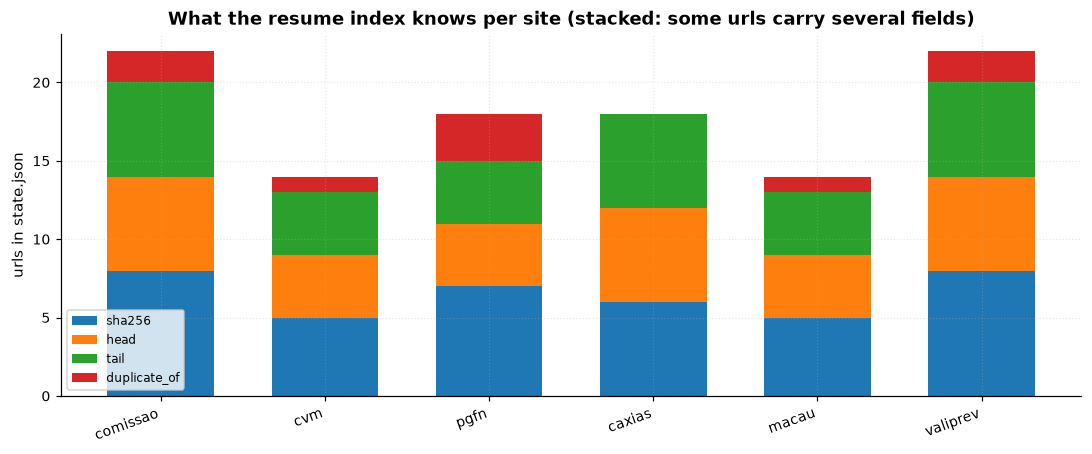

In [6]:
fields = ["sha256", "head", "tail", "listed_size", "content_type", "etag", "duplicate_of"]
cov = pd.DataFrame(
    {f: state.groupby("site")[f].apply(lambda s: s.notna().sum()) for f in fields if f in state}
)
cov.insert(0, "urls", state.groupby("site")["url"].count())
display(cov)

plot_cols = [c for c in ("sha256", "head", "tail", "duplicate_of") if c in cov.columns]
fig, ax = plt.subplots(figsize=(10, 4.2))
bottom = None
for col in plot_cols:
    vals = cov[col].to_numpy(dtype=float)
    ax.bar(range(len(cov)), vals, bottom=bottom, label=col, width=0.65)
    bottom = vals if bottom is None else bottom + vals
ax.set_xticks(range(len(cov)))
ax.set_xticklabels([d.short_site(s) for s in cov.index], rotation=20, ha="right")
ax.set_ylabel("urls in state.json")
ax.set_title("What the resume index knows per site (stacked: some urls carry several fields)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 3 · The audit trail and the error log

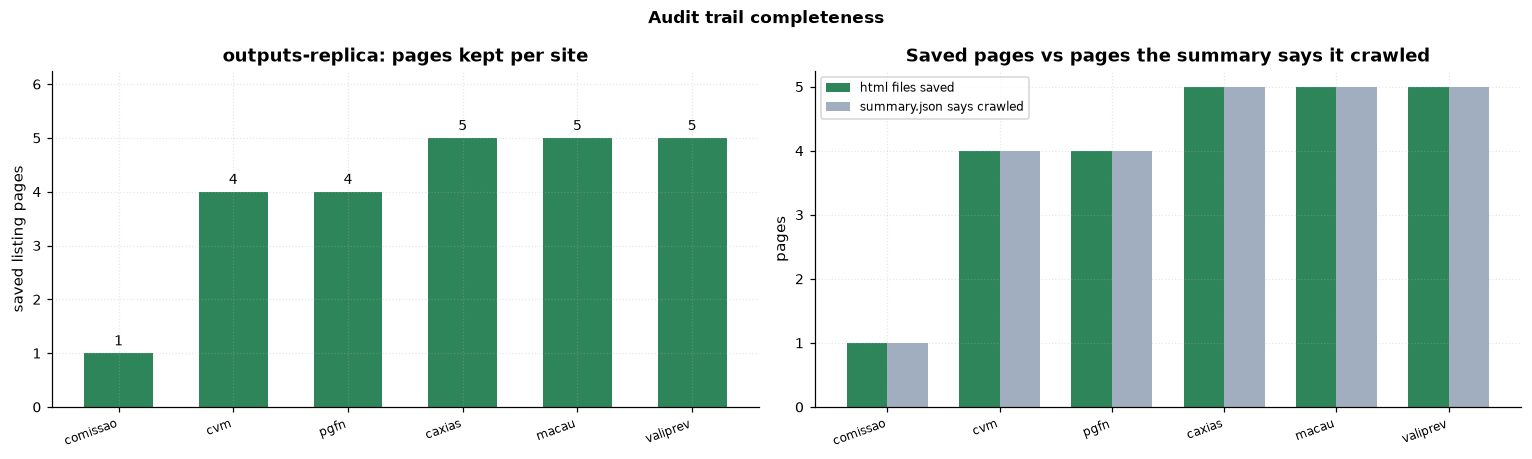

**errors.log, every site, both trees**

,tree,site,error lines,bytes
0,outputs,comissaodaverdade.al.sp.gov.br,0,0
1,outputs,dados.cvm.gov.br,0,0
2,outputs,dadosabertos.pgfn.gov.br,0,0
3,outputs,macau.rn.gov.br,0,0
4,outputs,valiprev.sp.gov.br,0,0
5,outputs-replica,comissaodaverdade.al.sp.gov.br,0,0
6,outputs-replica,dados.cvm.gov.br,0,0
7,outputs-replica,dadosabertos.pgfn.gov.br,0,0
8,outputs-replica,geofiles.caxias.rs.gov.br,0,0
9,outputs-replica,macau.rn.gov.br,0,0


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
rep = pages[pages["tree"] == "outputs-replica"].groupby("site").agg(pages=("path", "count"), bytes=("bytes", "sum"))
rep = rep.reindex(summary["site"]).fillna(0)

x = range(len(rep))
bars = axes[0].bar(x, rep["pages"].to_numpy(dtype=float), 0.6, color="#2f855a")
axes[0].bar_label(bars, padding=3, fontsize=9)
axes[0].set_xticks(list(x))
axes[0].set_xticklabels([d.short_site(s) for s in rep.index], rotation=20, ha="right", fontsize=8)
axes[0].set_ylabel("saved listing pages")
axes[0].set_title("outputs-replica: pages kept per site")
axes[0].set_ylim(0, rep["pages"].max() * 1.25)

reported = summary.set_index("site")["listing_pages"].reindex(rep.index).fillna(0)
w = 0.36
axes[1].bar([i - w / 2 for i in x], rep["pages"].to_numpy(dtype=float), w, label="html files saved", color="#2f855a")
axes[1].bar([i + w / 2 for i in x], reported.to_numpy(dtype=float), w, label="summary.json says crawled", color="#a0aec0")
axes[1].set_xticks(list(x))
axes[1].set_xticklabels([d.short_site(s) for s in rep.index], rotation=20, ha="right", fontsize=8)
axes[1].set_ylabel("pages")
axes[1].set_title("Saved pages vs pages the summary says it crawled")
axes[1].legend(fontsize=8)

fig.suptitle("Audit trail completeness", fontweight="bold")
fig.tight_layout()
plt.show()

err_lines = []
for tree in d.TREES:
    for site, path in d.site_dirs(tree):
        p = os.path.join(path, "_reports", "errors.log")
        n = sum(1 for line in open(p, encoding="utf-8") if line.strip()) if os.path.isfile(p) else 0
        err_lines.append({"tree": tree, "site": site, "error lines": n, "bytes": os.path.getsize(p) if os.path.isfile(p) else 0})
display(Markdown("**errors.log, every site, both trees**"))
display(pd.DataFrame(err_lines))

## 4 · Verdict

Everything the committed reports claim is reproducible from the bytes sitting
next to them: every document is present, every recorded size and SHA-256 matches
the file on disk, nothing errored, and the listing pages behind the numbers were
kept. The one thing a Git checkout cannot show is the hard links — re-run
`python3 tools/replica_demo.py` for that, or read the `sha256` columns.